# 06 · Respuestas desde datos: text-to-SQL seguro

Hay preguntas que ningún pasaje puede responder. *"¿Cuántas alarmas de nivel 3 tuvimos el año pasado?"*,
*"¿Qué turbina produjo más energía en 2025?"* piden un **número calculado a partir de filas**. Un modelo de
lenguaje al que se le pide contar filas pegadas en su prompt no es fiable (estima), y puede que la tabla ni
siquiera quepa. El diseño robusto es dejar que el modelo haga lo que se le da bien, *escribir una consulta*,
y que una base de datos haga lo que se le da bien, *calcular la respuesta*. Esto se llama **text-to-SQL**.

Es también la parte más peligrosa de un sistema RAG, porque se ejecuta un texto que produjo un modelo a
partir de un texto que escribió un usuario. Este módulo lo construye con un guardián que puedes probar como
cualquier otro código.

**Aprenderás**
1. Por qué los números necesitan una base de datos y no un prompt
2. Describir un esquema a un modelo (el prompt real) y un sustituto determinista que escribe la consulta
3. Un **guardián SQL** que permite exactamente un SELECT de solo lectura sobre vistas conocidas y bloquea todo lo demás, probado con cadenas de ataque
4. Defensa en profundidad: una base de datos de solo lectura sin acceso a archivos, un tope de filas y un tiempo máximo
5. Devolver un error al modelo para un reintento
6. Citar datos como un pasaje (`[data]` junto a `[1]`) y encaminar una pregunta a pasajes, a SQL o a ambos
7. Comprobar las respuestas SQL con un cálculo independiente

### Imagen: el modelo escribe, la base de datos calcula, y hay tres capas en medio

Léela de izquierda a derecha. El modelo solo produce **texto** (una consulta). Antes de que ese texto toque los datos pasa por un guardián
que acepta exactamente un SELECT de solo lectura sobre vistas conocidas; la propia base de datos está bloqueada (solo vistas, sin archivos,
un tope de filas y un tiempo límite). La respuesta es un número que sale de filas, con una cita `[data]`.

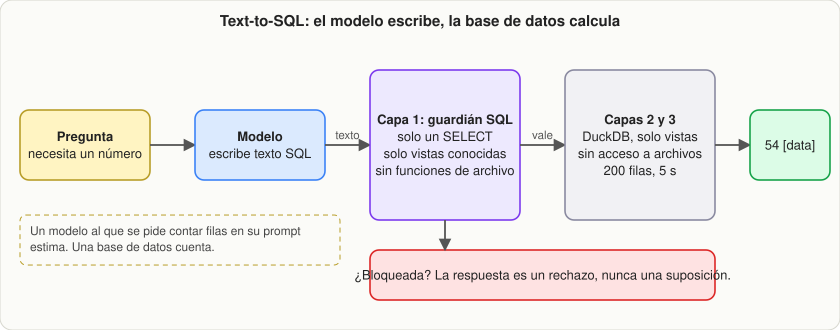

In [1]:
from IPython.display import SVG, display
import html as _h

_COL = {  # fill, stroke  (light cards with dark text: readable in light and dark themes)
    "gold": ("#fff4c2", "#b89d28"), "blue": ("#dbeafe", "#3b82f6"), "green": ("#dcfce7", "#16a34a"),
    "red": ("#fee2e2", "#dc2626"), "grey": ("#f1f1f4", "#8a8aa0"), "violet": ("#ede9fe", "#7c3aed"),
}

def diagram(width, height, items, title=None):
    # items: ("box", x, y, w, h, "text\nmore text", colour) | ("arrow", x1, y1, x2, y2, "label") |
    #        ("text", x, y, "text", size, "start|middle|end") | ("note", x, y, w, h, "text")
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" '
           f'font-family="Helvetica, Arial, sans-serif">',
           '<defs><marker id="ah" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" '
           'orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#555"/></marker></defs>',
           f'<rect width="{width}" height="{height}" rx="12" fill="#fbfbf8" stroke="#d8d8cf"/>']
    if title:
        out.append(f'<text x="{width / 2}" y="26" text-anchor="middle" font-size="15" font-weight="700" fill="#222">{_h.escape(title)}</text>')
    for it in items:
        kind = it[0]
        if kind == "box":
            _, x, y, w, h, text, col = it
            fill, stroke = _COL[col]
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="9" fill="{fill}" stroke="{stroke}" stroke-width="1.6"/>')
            lines = text.split("\n")
            y0 = y + h / 2 - (len(lines) - 1) * 8.5 + 4.5
            for k, ln in enumerate(lines):
                bold = ' font-weight="700"' if k == 0 and len(lines) > 1 else ""
                out.append(f'<text x="{x + w / 2}" y="{y0 + k * 17}" text-anchor="middle" font-size="13" fill="#222"{bold}>{_h.escape(ln)}</text>')
        elif kind == "arrow":
            _, x1, y1, x2, y2, label = it
            out.append(f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#555" stroke-width="1.8" marker-end="url(#ah)"/>')
            if label:
                out.append(f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 6}" text-anchor="middle" font-size="11.5" fill="#555">{_h.escape(label)}</text>')
        elif kind == "text":
            _, x, y, text, size, anchor = it
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x}" y="{y + k * (size + 4)}" text-anchor="{anchor}" font-size="{size}" fill="#333">{_h.escape(ln)}</text>')
        elif kind == "note":
            _, x, y, w, h, text = it
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="6" fill="none" stroke="#b89d28" stroke-dasharray="5 4"/>')
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x + 10}" y="{y + 20 + k * 16}" font-size="12" fill="#444">{_h.escape(ln)}</text>')
    out.append("</svg>")
    display(SVG("".join(out)))


diagram(840, 330, [
    ("box", 20, 110, 130, 70, "Pregunta\nnecesita un número", "gold"),
    ("arrow", 150, 145, 195, 145, ""),
    ("box", 195, 110, 130, 70, "Modelo\nescribe texto SQL", "blue"),
    ("arrow", 325, 145, 370, 145, "texto"),
    ("box", 370, 70, 150, 150, "Capa 1: guardián SQL\nsolo un SELECT\nsolo vistas conocidas\nsin funciones de archivo", "violet"),
    ("arrow", 520, 145, 565, 145, "vale"),
    ("box", 565, 70, 150, 150, "Capas 2 y 3\nDuckDB, solo vistas\nsin acceso a archivos\n200 filas, 5 s", "grey"),
    ("arrow", 715, 145, 750, 145, ""),
    ("box", 750, 110, 80, 70, "54 [data]", "green"),
    ("box", 370, 250, 345, 50, "¿Bloqueada? La respuesta es un rechazo, nunca una suposición.", "red"),
    ("arrow", 445, 220, 445, 250, ""),
    ("note", 20, 215, 320, 50, "Un modelo al que se pide contar filas en su prompt\nestima. Una base de datos cuenta."),
], "Text-to-SQL: el modelo escribe, la base de datos calcula")

## 1. Los datos

Un pequeño conjunto de datos sintético del parque Harbourview, generado aquí para que el notebook sea
autocontenido: `turbines` (una fila por turbina), `work_orders` (trabajos de mantenimiento con un nivel de
alarma) y `monthly_output` (energía por turbina y mes). Se carga en DuckDB, una base de datos analítica
dentro del propio proceso que no necesita servidor y carga directamente filas de Python.

In [2]:
# El manual de Harbourview: 22 pasajes, ficticio, escrito para este curso
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

# (id, pregunta, pasaje correcto, dato que debe contener la respuesta); None = el manual no lo dice
QUESTIONS = [
    ["q01", "What wave height stops the crew boats from sailing?", "p02", "1.5 m"],
    ["q02", "How often is the gearbox oil sampled?", "p07", "six months"],
    ["q03", "Who may work alone inside a nacelle?", "p03", "forbidden"],
    ["q04", "What is the rotor diameter of a turbine?", "p04", "164 m"],
    ["q05", "What do I do if the pitch fault comes back after a reset?", "p10", "replace the hydraulic accumulator"],
    ["q06", "When must a Level 3 alarm be attended on site?", "p09", "24 hours"],
    ["q07", "How soon must an injury be reported?", "p19", "one hour"],
    ["q08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", "300 MW"],
    ["q09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", "HV01 to HV08"],
    ["q10", "How many spare wind vanes are kept in stock?", "p16", "four wind vanes"],
    ["q11", "What qualification do I need before getting on the boat?", "p01", "GWO Basic Safety Training"],
    ["q12", "When can the turbines restart after a blackout?", "p12", "10 minutes"],
    ["q13", "When can a helicopter be used?", "p17", "medical evacuation"],
    ["q14", "What happens when a dolphin is seen near the piling work?", "p13", "pause"],
    ["q15", "What is the price of electricity per MWh?", None, None],
    ["q16", "Who is the chief executive of the operating company?", None, None],
]

In [3]:
import re, json, math, time, threading, textwrap, datetime
import numpy as np, duckdb

rng = np.random.default_rng(42)
turbines = [(f"HV{i:02d}", 8.0, int(y)) for i, y in zip(range(1, 41), rng.choice([2022, 2023], 40, p=[.6, .4]))]
months = [f"2025-{m:02d}" for m in range(1, 13)]
season = {m: 1.25 - 0.45 * math.cos((int(m[5:]) - 1) / 12 * 2 * math.pi) / 2 for m in months}
monthly_output = [(t[0], m, round(float(8.0 * 24 * 30 * 0.38 * season[m] * rng.normal(1, .06)), 1)) for t in turbines for m in months]
cats = ["gearbox", "pitch", "yaw", "blade", "grid", "other"]
n = 300
day0 = datetime.date(2025, 1, 1)
work_orders = []
for i in range(1, n + 1):
    status = str(rng.choice(["closed", "open"], p=[.9, .1]))
    work_orders.append((f"WO{i:04d}", str(rng.choice([t[0] for t in turbines])), day0 + datetime.timedelta(days=int(rng.integers(0, 365))),
                        str(rng.choice(cats, p=[.15, .25, .15, .15, .1, .2])), int(rng.choice([1, 2, 3], p=[.45, .4, .15])),
                        round(float(rng.gamma(2.0, 14.0)), 1) if status == "closed" else None, status))
print(len(turbines), "turbines,", len(work_orders), "work orders,", len(monthly_output), "monthly output rows")
for row in work_orders[:3]:
    print(row)

40 turbines, 300 work orders, 480 monthly output rows
('WO0001', 'HV09', datetime.date(2025, 11, 3), 'other', 1, 59.0, 'closed')
('WO0002', 'HV34', datetime.date(2025, 10, 3), 'yaw', 2, 17.4, 'closed')
('WO0003', 'HV38', datetime.date(2025, 1, 17), 'pitch', 1, None, 'open')


## 2. La base de datos: solo vistas, sin acceso a archivos

El modelo nunca ve los nombres de tabla del almacenamiento real. Cargamos los datos en tablas, exponemos tres
**vistas** con nombres cortos y documentados, y después bloqueamos la conexión: **sin acceso al sistema de
archivos ni a la red** y sin cambios de configuración. Aunque una consulta se colara por todos los demás
controles, no podría leer `/etc/passwd`.

In [4]:
con = duckdb.connect(":memory:")
con.execute("CREATE TABLE t_turbines (turbine_id VARCHAR, rated_mw DOUBLE, commissioned INTEGER)")
con.execute("CREATE TABLE t_work_orders (wo_id VARCHAR, turbine_id VARCHAR, opened DATE, category VARCHAR, alarm_level INTEGER, hours_to_close DOUBLE, status VARCHAR)")
con.execute("CREATE TABLE t_monthly_output (turbine_id VARCHAR, month VARCHAR, energy_mwh DOUBLE)")
con.executemany("INSERT INTO t_turbines VALUES (?, ?, ?)", turbines)
con.executemany("INSERT INTO t_work_orders VALUES (?, ?, ?, ?, ?, ?, ?)", work_orders)
con.executemany("INSERT INTO t_monthly_output VALUES (?, ?, ?)", monthly_output)
con.execute("CREATE VIEW turbines AS SELECT * FROM t_turbines")
con.execute("CREATE VIEW work_orders AS SELECT * FROM t_work_orders")
con.execute("CREATE VIEW monthly_output AS SELECT * FROM t_monthly_output")
con.execute("SET enable_external_access = false")      # sin archivos, sin red
con.execute("SET lock_configuration = true")           # el ajuste anterior ya no se puede cambiar

try:
    con.execute("SELECT * FROM read_csv('/etc/passwd')")
except Exception as e:
    print("file access:", str(e).split(chr(10))[0][:110])
try:
    con.execute("SET enable_external_access = true")
except Exception as e:
    print("unlock attempt:", str(e).split(chr(10))[0][:110])

VIEWS = {
    "turbines": "one row per turbine: turbine_id (e.g. HV07), rated_mw, commissioned (year)",
    "work_orders": "maintenance jobs of 2025: wo_id, turbine_id, opened (date), category (gearbox|pitch|yaw|blade|grid|other), alarm_level (1-3), hours_to_close (NULL while open), status (closed|open)",
    "monthly_output": "energy per turbine and month of 2025: turbine_id, month ('YYYY-MM'), energy_mwh",
}
SCHEMA = "\n".join(f"- {v}: {d}" for v, d in VIEWS.items())
print(SCHEMA)

file access: Permission Error: Cannot access file "/etc/passwd" - file system operations are disabled by configuration
unlock attempt: Invalid Input Error: Cannot change configuration option ""enable_external_access"" - the configuration has bee
- turbines: one row per turbine: turbine_id (e.g. HV07), rated_mw, commissioned (year)
- work_orders: maintenance jobs of 2025: wo_id, turbine_id, opened (date), category (gearbox|pitch|yaw|blade|grid|other), alarm_level (1-3), hours_to_close (NULL while open), status (closed|open)
- monthly_output: energy per turbine and month of 2025: turbine_id, month ('YYYY-MM'), energy_mwh


## 3. El modelo escribe la consulta (el prompt y un sustituto)

Esta es la forma del prompt real. Importan tres cosas: el modelo ve **solo** las vistas documentadas, se le
pide que responda con **un** SELECT y se le dice qué hacer cuando los datos no pueden responder.

In [5]:
SQL_PROMPT = '''You write one read-only DuckDB SQL query that answers the user's question from these views:
{schema}
Rules:
- Return ONLY the SQL, a single SELECT (or WITH ... SELECT). No comments, no explanation.
- Use only the views and columns listed above.
- Aggregate in SQL: never return raw rows when the question asks for a count, a total or a ranking.
- If the views cannot answer the question, return exactly: NO_QUERY
Question: {question}'''
print(SQL_PROMPT.format(schema=SCHEMA, question="How many work orders were opened in March?"))

You write one read-only DuckDB SQL query that answers the user's question from these views:
- turbines: one row per turbine: turbine_id (e.g. HV07), rated_mw, commissioned (year)
- work_orders: maintenance jobs of 2025: wo_id, turbine_id, opened (date), category (gearbox|pitch|yaw|blade|grid|other), alarm_level (1-3), hours_to_close (NULL while open), status (closed|open)
- monthly_output: energy per turbine and month of 2025: turbine_id, month ('YYYY-MM'), energy_mwh
Rules:
- Return ONLY the SQL, a single SELECT (or WITH ... SELECT). No comments, no explanation.
- Use only the views and columns listed above.
- Aggregate in SQL: never return raw rows when the question asks for a count, a total or a ranking.
- If the views cannot answer the question, return exactly: NO_QUERY
Question: How many work orders were opened in March?


En el notebook ejecutado no se llama a ningún modelo. La función siguiente es un **sustituto determinista**:
un puñado de plantillas que hacen el papel del modelo para que cada resultado sea reproducible. También
reproduce el error real más común de un modelo, *inventar el nombre de una columna* (`produced_mwh` en lugar
de `energy_mwh`), para poder probar con honestidad el reintento con el error. Una celda opcional al final del
notebook cambia el sustituto por un modelo real mediante LiteLLM cuando defines una variable de entorno.

In [6]:
import difflib

COLUMNS = {"turbines": ["turbine_id", "rated_mw", "commissioned"],
           "work_orders": ["wo_id", "turbine_id", "opened", "category", "alarm_level", "hours_to_close", "status"],
           "monthly_output": ["turbine_id", "month", "energy_mwh"]}

def stand_in_writer(question, error=None, previous=None):
    q = question.lower()
    if error and previous:                                     # reintento: reparar una columna desconocida a partir del texto del error
        bad = re.search(r'Referenced column "([^"]+)"', error)
        view = re.search(r"\bFROM\s+(\w+)", previous, re.I)
        if bad and view and view.group(1) in COLUMNS:
            close = difflib.get_close_matches(bad.group(1), COLUMNS[view.group(1)], n=1, cutoff=0.0)
            return previous.replace(bad.group(1), close[0])
        return previous
    m = re.search(r"level (\d)", q)
    if "work order" in q and "level" in q and m:
        return f"SELECT count(*) AS n FROM work_orders WHERE alarm_level = {m.group(1)}"
    if "work order" in q and ("how many" in q) and re.search(r"opened in (\w+)", q):
        month = {"january": 1, "february": 2, "march": 3, "april": 4, "may": 5, "june": 6}.get(re.search(r"opened in (\w+)", q).group(1))
        if month:
            return f"SELECT count(*) AS n FROM work_orders WHERE month(opened) = {month}"
    if "most energy" in q or "produced the most" in q:
        return "SELECT turbine_id, sum(produced_mwh) AS total_mwh FROM monthly_output GROUP BY turbine_id ORDER BY total_mwh DESC LIMIT 1"
    if "commissioned in" in q:
        y = re.search(r"commissioned in (\d{4})", q).group(1)
        return f"SELECT count(*) AS n FROM turbines WHERE commissioned = {y}"
    if "total" in q and "output" in q:
        mon = re.search(r"in (\w+)", q)
        num = {"january": 1, "february": 2, "march": 3, "april": 4, "may": 5, "june": 6, "july": 7, "august": 8}.get(mon.group(1)) if mon else None
        if num:
            return f"SELECT round(sum(energy_mwh), 1) AS total_mwh FROM monthly_output WHERE month = '2025-{num:02d}'"
    if "average" in q and "hours" in q and "pitch" in q:
        return "SELECT round(avg(hours_to_close), 1) AS avg_hours FROM work_orders WHERE category = 'pitch' AND status = 'closed'"
    return "NO_QUERY"

print(stand_in_writer("How many Level 3 work orders were there?"))

SELECT count(*) AS n FROM work_orders WHERE alarm_level = 3


## 4. El guardián SQL

El texto que viene de un modelo es una entrada no confiable. El guardián decide si una consulta puede
ejecutarse y debe ser **estricto por construcción**: en lugar de buscar palabras peligrosas en el texto (fácil
de esquivar con comentarios, comillas o mayúsculas), pide al propio analizador de DuckDB el **árbol de
sintaxis** y comprueba el árbol:

1. exactamente **una** sentencia;
2. esa sentencia es un **SELECT** (DuckDB se niega a serializar cualquier otra cosa, así que `DROP`, `INSERT`, `COPY`, `ATTACH` y `PRAGMA` fallan aquí);
3. cada tabla que lee es una de nuestras **vistas** o una CTE definida en la propia consulta, **sin prefijo de esquema**;
4. **ninguna función de tabla** (`read_csv`, `read_parquet`, `glob`, `range`...), que son la vía por la que entran archivos y generadores.

Un guardián basado en el analizador no se deja engañar por `/* DROP */` ni por `ReAd_CsV`, porque nunca lee
el texto como lo haría una persona.

In [7]:
class Blocked(Exception):
    pass

def tables_of(node, out):
    if isinstance(node, dict):
        if node.get("type") in ("BASE_TABLE", "TABLE_FUNCTION"):
            out.append((node["type"], node.get("table_name"), node.get("schema_name") or ""))
        for v in node.values():
            tables_of(v, out)
    elif isinstance(node, list):
        for v in node:
            tables_of(v, out)

def cte_names(tree):
    names = set()
    def walk(node):
        if isinstance(node, dict):
            if "cte_map" in node:
                names.update(e["key"] for e in node["cte_map"]["map"])
            for v in node.values():
                walk(v)
        elif isinstance(node, list):
            for v in node:
                walk(v)
    walk(tree)
    return names

def guard(sql):
    sql = sql.strip().rstrip(";").strip()
    if not sql:
        raise Blocked("empty query")
    if len(con.extract_statements(sql)) != 1:
        raise Blocked("more than one statement")
    tree = json.loads(con.execute("SELECT json_serialize_sql(?)", [sql]).fetchone()[0])
    if tree.get("error"):
        raise Blocked("not a plain SELECT: " + tree.get("error_message", "")[:60])
    refs = []
    tables_of(tree, refs)
    ctes = cte_names(tree)
    for kind, name, schema in refs:
        if kind == "TABLE_FUNCTION":
            raise Blocked("table functions are not allowed")
        if schema:
            raise Blocked(f"schema-qualified table {schema}.{name}")
        if name not in VIEWS and name not in ctes:
            raise Blocked(f"unknown table {name!r} (allowed: {', '.join(VIEWS)})")
    return sql

LEGIT = [
    "SELECT count(*) FROM work_orders WHERE alarm_level = 3",
    "SELECT turbine_id, sum(energy_mwh) AS t FROM monthly_output GROUP BY 1 ORDER BY t DESC LIMIT 3",
    "WITH l3 AS (SELECT turbine_id FROM work_orders WHERE alarm_level = 3) SELECT count(DISTINCT turbine_id) FROM l3",
    "SELECT w.category, count(*) FROM work_orders w JOIN turbines t USING (turbine_id) WHERE t.commissioned = 2022 GROUP BY 1",
    "select 1 /* a harmless comment */ as one",
]
ATTACKS = [
    "DROP TABLE t_work_orders",
    "SELECT 1; DROP TABLE t_work_orders",
    "SELECT * FROM work_orders; SELECT * FROM turbines",
    "DELETE FROM work_orders",
    "INSERT INTO turbines VALUES ('X', 1, 2020)",
    "CREATE TABLE x AS SELECT * FROM turbines",
    "COPY work_orders TO '/tmp/leak.csv'",
    "ATTACH '/tmp/other.db' AS o",
    "PRAGMA database_list",
    "SET enable_external_access = true",
    "SELECT * FROM read_csv('/etc/passwd')",
    "SELECT * FROM ReAd_CsV('/etc/passwd')",
    "SELECT * FROM read_parquet('/data/*.parquet')",
    "SELECT * FROM glob('/home/*')",
    "SELECT * FROM range(1000000000)",
    "SELECT * FROM t_work_orders",
    "SELECT * FROM main.work_orders",
    "SELECT * FROM information_schema.tables",
    "SELECT * FROM duckdb_settings()",
    "/* DROP TABLE x */ SELECT 1; DROP TABLE x",
    "SELECT * FROM work_orders, secrets",
    "WITH x AS (SELECT * FROM read_csv('/etc/passwd')) SELECT * FROM x",
    "SELECT (SELECT count(*) FROM t_turbines)",
]

def check(sql):
    try:
        guard(sql); return "allowed"
    except Blocked as e:
        return "blocked: " + str(e)
    except Exception as e:
        return "blocked (parser): " + str(e).split(chr(10))[0][:50]

print("LEGITIMATE QUERIES")
for s in LEGIT:
    print(f"  {check(s)[:11]:12s} {s[:80]}")
print("\nATTACKS")
res = [(s, check(s)) for s in ATTACKS]
for s, r in res:
    print(f"  {r[:62]:62s} {s[:60]}")
assert all(check(s) == "allowed" for s in LEGIT), "a legitimate query was blocked"
assert all(r.startswith("blocked") for _, r in res), "an attack got through"
print(f"\n{sum(check(s) == 'allowed' for s in LEGIT)}/{len(LEGIT)} legitimate queries pass, {sum(r.startswith('blocked') for _, r in res)}/{len(ATTACKS)} attacks blocked")

LEGITIMATE QUERIES
  allowed      SELECT count(*) FROM work_orders WHERE alarm_level = 3
  allowed      SELECT turbine_id, sum(energy_mwh) AS t FROM monthly_output GROUP BY 1 ORDER BY 
  allowed      WITH l3 AS (SELECT turbine_id FROM work_orders WHERE alarm_level = 3) SELECT cou
  allowed      SELECT w.category, count(*) FROM work_orders w JOIN turbines t USING (turbine_id
  allowed      select 1 /* a harmless comment */ as one

ATTACKS
  blocked: not a plain SELECT: Only SELECT statements can be ser DROP TABLE t_work_orders
  blocked: more than one statement                               SELECT 1; DROP TABLE t_work_orders
  blocked: more than one statement                               SELECT * FROM work_orders; SELECT * FROM turbines
  blocked: not a plain SELECT: Only SELECT statements can be ser DELETE FROM work_orders
  blocked: not a plain SELECT: Only SELECT statements can be ser INSERT INTO turbines VALUES ('X', 1, 2020)
  blocked: not a plain SELECT: Only SELECT statements ca

Todos los ataques se detienen, y cada uno por un **motivo con nombre**, lo que importa en producción: el
motivo se registra (módulo 08) y se muestra al modelo para su reintento. Fíjate en los dos casos que
bloqueamos aunque no sean obviamente peligrosos: `t_work_orders` (una tabla base que no forma parte del mundo
documentado del modelo) e `information_schema` (permitiría a un modelo, o a un usuario, explorar el esquema).
*Mínimo privilegio* significa que el modelo recibe las vistas que necesita y nada más.

El guardián es la primera de **tres capas**. La segunda es la conexión bloqueada de la sección 2 (ni acceso a
archivos ni a la red aunque el guardián tuviera un fallo). La tercera limita lo que puede costar una consulta
legítima: un tope de filas y un tiempo máximo.

## 5. Ejecutarla: tope de filas, tiempo máximo y un reintento con el error

* **Tope de filas**: recuperar como mucho 200 filas e indicar cuándo el resultado se truncó. Un modelo que
  olvidó un `LIMIT` no debe poder meter un millón de filas en el siguiente prompt.
* **Tiempo máximo**: un hilo vigilante llama a `con.interrupt()` pasado un plazo. Lo demostramos con una
  consulta que el guardián nunca permitiría (un rango de mil millones de filas), para mostrar que la *tercera*
  capa funciona por sí sola.
* **Reintento con el error**: si la consulta falla (una columna que no existe), se devuelve **una vez** el
  mensaje de error de la base de datos al modelo. Dos intentos es un buen valor por defecto: un segundo fallo
  suele significar que la pregunta no se puede responder con estas vistas, y seguir iterando solo gasta tokens.

### Imagen: una pregunta a través del bucle de reintento

Este es el recorrido de los datos del primer ejemplo de reintento, más abajo. El escritor sustituto comete el error real más común:
inventar la columna `produced_mwh`. El guardián deja pasar la consulta, porque es un SELECT válido sobre una vista conocida,
y la base de datos la rechaza con un error de enlace. Ese error vuelve una vez al escritor; la consulta reparada devuelve
`HV23`, que coincide con el cálculo independiente.

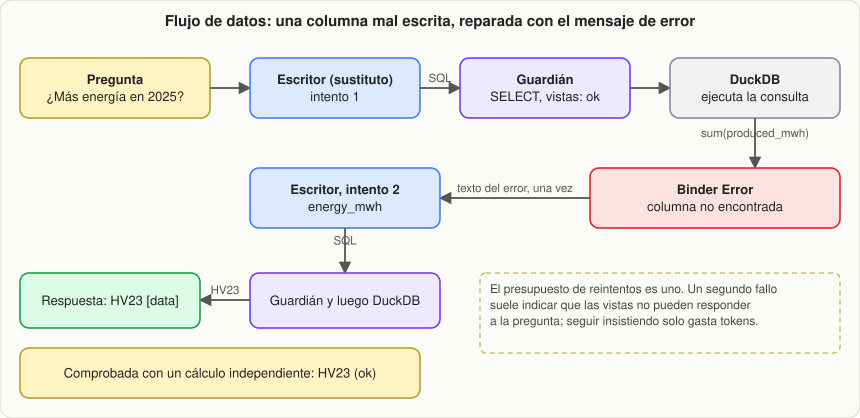

In [8]:
diagram(860, 418, [
    ("box", 20, 58, 190, 60, "Pregunta\n¿Más energía en 2025?", "gold"),
    ("arrow", 210, 88, 250, 88, ""),
    ("box", 250, 58, 170, 60, "Escritor (sustituto)\nintento 1", "blue"),
    ("arrow", 420, 88, 460, 88, "SQL"),
    ("box", 460, 58, 170, 60, "Guardián\nSELECT, vistas: ok", "violet"),
    ("arrow", 630, 88, 670, 88, ""),
    ("box", 670, 58, 170, 60, "DuckDB\nejecuta la consulta", "grey"),
    ("arrow", 755, 118, 755, 168, "sum(produced_mwh)"),
    ("box", 590, 168, 250, 60, "Binder Error\ncolumna no encontrada", "red"),
    ("arrow", 590, 198, 440, 198, "texto del error, una vez"),
    ("box", 250, 168, 190, 60, "Escritor, intento 2\nenergy_mwh", "blue"),
    ("arrow", 345, 228, 345, 273, "SQL"),
    ("box", 250, 273, 190, 55, "Guardián y luego DuckDB", "violet"),
    ("arrow", 250, 300, 200, 300, "HV23"),
    ("box", 20, 273, 180, 55, "Respuesta: HV23 [data]", "green"),
    ("box", 20, 348, 400, 50, "Comprobada con un cálculo independiente: HV23 (ok)", "gold"),
    ("note", 480, 273, 360, 80, "El presupuesto de reintentos es uno. Un segundo fallo\nsuele indicar que las vistas no pueden responder\na la pregunta; seguir insistiendo solo gasta tokens."),
], "Flujo de datos: una columna mal escrita, reparada con el mensaje de error")

In [9]:
MAX_ROWS, TIMEOUT_S = 200, 5.0

def run_sql(sql, timeout=TIMEOUT_S):
    sql = guard(sql)
    timer = threading.Timer(timeout, con.interrupt)
    timer.start()
    try:
        cur = con.execute(sql)
        rows = cur.fetchmany(MAX_ROWS + 1)
        cols = [d[0] for d in cur.description]
    finally:
        timer.cancel()
    return dict(sql=sql, columns=cols, rows=[list(r) for r in rows[:MAX_ROWS]], truncated=len(rows) > MAX_ROWS)

# la tercera capa por sí sola: el guardián rechazaría esta consulta, así que se llama directamente a la base de datos
t0 = time.time()
timer = threading.Timer(0.5, con.interrupt); timer.start()
try:
    con.execute("SELECT count(*) FROM generate_series(1, 100000000000)").fetchall()
except Exception as e:
    print(f"interrupted after {time.time() - t0:.2f} s:", type(e).__name__)
finally:
    timer.cancel()

def answer_with_sql(question, writer=stand_in_writer):
    attempts = []
    sql = writer(question)
    if sql.strip() == "NO_QUERY":
        return dict(status="no_query", attempts=attempts)
    error = None
    for attempt in (1, 2):
        try:
            result = run_sql(sql)
            attempts.append(dict(sql=sql, error=None))
            return dict(status="ok", result=result, attempts=attempts)
        except Exception as e:
            error = str(e).split(chr(10))[0]
            attempts.append(dict(sql=sql, error=error))
            if isinstance(e, Blocked) or attempt == 2:
                break
            sql = writer(question, error=error, previous=sql)
    return dict(status="failed", attempts=attempts)

out = answer_with_sql("Which turbine produced the most energy in 2025?")
for a in out["attempts"]:
    print("attempt:", a["sql"][:95], "\n   error:", a["error"])
print("result:", out["result"]["columns"], out["result"]["rows"])

interrupted after 0.50 s: InterruptException
attempt: SELECT turbine_id, sum(produced_mwh) AS total_mwh FROM monthly_output GROUP BY turbine_id ORDER 
   error: Binder Error: Referenced column "produced_mwh" not found in FROM clause!
attempt: SELECT turbine_id, sum(energy_mwh) AS total_mwh FROM monthly_output GROUP BY turbine_id ORDER B 
   error: None
result: ['turbine_id', 'total_mwh'] [['HV23', 34052.399999999994]]


El primer intento falló con el mensaje de la propia base de datos, el sustituto reparó la columna a partir de
ese mensaje (un modelo real hace lo mismo con el esquema en su prompt) y el segundo intento se ejecutó. Se
guarda el registro de **ambos** intentos: una pregunta que necesita un reintento es una señal sobre el prompt,
no sobre el usuario.

## 6. Citar datos como un pasaje

Una respuesta desde datos es tan inverificable como una respuesta de memoria si no muestra de dónde sale.
Citamos los pasajes como `[1]`, `[2]` y el resultado de la consulta como **`[data]`**, y guardamos el SQL junto
a la respuesta para que un lector (o el supervisor del módulo 08) pueda volver a ejecutarlo.

In [10]:
STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())
def tokens(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.tf = [{} for _ in docs]
        for i, d in enumerate(docs):
            for t in tokens(d):
                self.tf[i][t] = self.tf[i].get(t, 0) + 1
        self.len = np.array([sum(tf.values()) for tf in self.tf], dtype=float); self.avg = self.len.mean()
        df = {}
        for tf in self.tf:
            for t in tf:
                df[t] = df.get(t, 0) + 1
        self.idf = {t: math.log(1 + (len(docs) - c + 0.5) / (c + 0.5)) for t, c in df.items()}
    def scores(self, query):
        s = np.zeros(len(self.tf))
        for t in set(tokens(query)):
            if t in self.idf:
                for i, tf in enumerate(self.tf):
                    f = tf.get(t, 0)
                    if f:
                        s[i] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg))
        return s

ids = [p[0] for p in PASSAGES]
chunks = [f"{section}. {text}" for _, section, text in PASSAGES]
bm25 = BM25(chunks)

def best_sentence(question, passage_idx):
    section, text = chunks[passage_idx].split(". ", 1)
    q = set(tokens(question))
    return max(re.split(r"(?<=[.!?])\s+", text), key=lambda s: len(q & set(tokens(s)))), section

def format_data(out):
    cols, rows = out["result"]["columns"], out["result"]["rows"]
    if len(rows) == 1 and len(cols) == 1:
        return f"{cols[0]} = {rows[0][0]}"
    return "; ".join(", ".join(f"{c} = {v}" for c, v in zip(cols, r)) for r in rows[:5])

def respond(question, route):
    parts, sources = [], []
    if route in ("sql", "both"):
        out = answer_with_sql(question)
        if out["status"] == "ok":
            parts.append(f"From the data: {format_data(out)} [data].")
            sources.append(("data", out["attempts"][-1]["sql"]))
    if route in ("passages", "both"):
        s = bm25.scores(question); i = int(np.argmax(s))
        if s[i] >= 1.0:
            sent, section = best_sentence(question, i)
            parts.append(f"{sent} [1]")
            sources.append((1, f"{ids[i]} {section}"))
    return (" ".join(parts) or "I cannot answer that from the handbook or the data."), sources

ans, src = respond("How many Level 3 work orders were there, and how quickly must a Level 3 alarm be attended?", "both")
print(ans); print(src)

From the data: n = 54 [data]. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows. [1]
[('data', 'SELECT count(*) AS n FROM work_orders WHERE alarm_level = 3'), (1, 'p09 Faults / Alarm levels')]


## 7. Enrutado: pasajes, SQL o ambos

¿Qué camino necesita una pregunta? Un enrutador barato y transparente es un buen comienzo: *números y
clasificaciones sobre nuestros propios registros* van a SQL, *reglas y procedimientos* van a pasajes, y una
pregunta que mezcla ambos va a los dos. Lo probamos con una batería etiquetada, porque un enrutador es un
clasificador y merece una medición.

In [11]:
DATA_WORDS = re.compile(r"\b(how many|total|average|mean|most|least|highest|lowest|sum|number of|count)\b", re.I)
DATA_NOUNS = re.compile(r"\b(work orders?|turbines?|output|energy|mwh|alarms?|opened|commissioned)\b", re.I)
RULE_WORDS = re.compile(r"\b(must|should|allowed|limit|rule|procedure|how (?:quickly|soon|often|fast)|when can|what is the|who)\b", re.I)

def route(question):
    wants_data = bool(DATA_WORDS.search(question) and DATA_NOUNS.search(question))
    wants_rule = bool(RULE_WORDS.search(question)) or not wants_data
    if wants_data and re.search(r"\band\b.*\b(must|how (?:quickly|soon|often|fast)|what is the (?:rule|limit))", question, re.I):
        return "both"
    return "sql" if wants_data and not RULE_WORDS.search(question) else ("both" if wants_data else "passages")

ROUTE_BATTERY = [
    ("How many Level 3 work orders were there?", "sql"),
    ("Which turbine produced the most energy in 2025?", "sql"),
    ("What was the total output in March in MWh?", "sql"),
    ("How many turbines were commissioned in 2023?", "sql"),
    ("What is the average number of hours to close a pitch work order?", "sql"),
    ("What wave height stops the crew boats from sailing?", "passages"),
    ("How often is the gearbox oil sampled?", "passages"),
    ("When can a helicopter be used?", "passages"),
    ("How many Level 3 work orders were there, and how quickly must a Level 3 alarm be attended?", "both"),
    ("Who is the chief executive of the operating company?", "none"),
]
right = 0
for q, expected in ROUTE_BATTERY:
    got = route(q)
    ok = got == expected or (expected == "none" and got == "passages")   # 'none' no tiene ruta: pasajes y luego se niega
    right += ok
    print(f"{'ok ' if ok else 'MISS'} expected {expected:9s} got {got:9s} {q[:70]}")
print(f"\nrouting: {right}/{len(ROUTE_BATTERY)}")

ok  expected sql       got sql       How many Level 3 work orders were there?
ok  expected sql       got sql       Which turbine produced the most energy in 2025?
ok  expected sql       got sql       What was the total output in March in MWh?
ok  expected sql       got sql       How many turbines were commissioned in 2023?
MISS expected sql       got both      What is the average number of hours to close a pitch work order?
ok  expected passages  got passages  What wave height stops the crew boats from sailing?
ok  expected passages  got passages  How often is the gearbox oil sampled?
ok  expected passages  got passages  When can a helicopter be used?
ok  expected both      got both      How many Level 3 work orders were there, and how quickly must a Level 
ok  expected none      got passages  Who is the chief executive of the operating company?

routing: 9/10


El enrutador acierta 9 de 10. El fallo es instructivo: *"What is the average number of hours ..."* contiene la
expresión *"what is the"*, que nuestra regla toma como señal de pregunta de reglas, así que envía una pregunta
puramente de datos a ambos caminos (inofensivo pero derrochador: también recupera un pasaje). La pregunta del
director ejecutivo se cuenta como correcta porque el camino de pasajes no encuentra nada por encima del umbral
y la respuesta se niega. Lee los fallos como una lista de tareas para el enrutador, no como un fallo de la idea.
En producción el enrutador suele ser **el propio modelo** (se le dice que tiene dos herramientas, una búsqueda
de pasajes y una consulta SQL, y elige), que es lo que hacen los agentes del módulo 05; un enrutador por reglas
como este es la referencia que hay que superar y un respaldo útil cuando el modelo no está disponible.

## 8. Comprobar las respuestas con un cálculo independiente

¿Cómo sabemos que las respuestas SQL son correctas? Igual que con cualquier componente: comparando con una
referencia calculada **de forma independiente**, aquí con Python puro sobre las filas originales en lugar de
SQL. El módulo 07 convierte esto en un hábito de evaluación completo: *la referencia nunca debe salir del
sistema que se evalúa.*

In [12]:
QA = [
    ("How many Level 3 work orders were there?", sum(w[4] == 3 for w in work_orders)),
    ("How many turbines were commissioned in 2023?", sum(t[2] == 2023 for t in turbines)),
    ("What was the total output in March in MWh?", round(sum(r[2] for r in monthly_output if r[1] == "2025-03"), 1)),
    ("What is the average number of hours to close a pitch work order?",
     round(float(np.mean([w[5] for w in work_orders if w[3] == "pitch" and w[6] == "closed"])), 1)),
    ("Which turbine produced the most energy in 2025?", max(totals := {t[0]: sum(r[2] for r in monthly_output if r[0] == t[0]) for t in turbines}, key=totals.get)),
]
for q, ref in QA:
    out = answer_with_sql(q)
    got = out["result"]["rows"][0][0] if out["status"] == "ok" else None
    ok = got == ref
    print(f"{'ok  ' if ok else 'FAIL'} {q[:62]:62s} sql={got!s:>8}  reference={ref!s:>8}  retries={len(out['attempts']) - 1}")

ok   How many Level 3 work orders were there?                       sql=      54  reference=      54  retries=0
ok   How many turbines were commissioned in 2023?                   sql=      19  reference=      19  retries=0
ok   What was the total output in March in MWh?                     sql= 99600.0  reference= 99600.0  retries=0
ok   What is the average number of hours to close a pitch work orde sql=    25.4  reference=    25.4  retries=0
ok   Which turbine produced the most energy in 2025?                sql=    HV23  reference=    HV23  retries=1


## 9. Opcional: un modelo real escribe el SQL

El notebook ejecutado nunca llama a un modelo. Para probar uno real, define `RAG_LIVE_MODEL` con el nombre de
un modelo de LiteLLM (por ejemplo un modelo Amazon Nova de Bedrock, o cualquier modelo alojado para el que
tengas clave) y vuelve a ejecutar esta celda. Se conecta exactamente al mismo guardián, ejecutor y reintento,
que es lo importante: **la seguridad no depende del modelo**. Sin la variable, la celda no hace nada.

In [13]:
import os

def litellm_writer(question, error=None, previous=None):
    import litellm
    prompt = SQL_PROMPT.format(schema=SCHEMA, question=question)
    if error:
        prompt += f"\n\nYour previous query:\n{previous}\nfailed with:\n{error}\nReturn a corrected query."
    r = litellm.completion(model=os.environ["RAG_LIVE_MODEL"], messages=[{"role": "user", "content": prompt}], temperature=0)
    return r.choices[0].message.content.strip().strip("`").removeprefix("sql").strip()

if os.getenv("RAG_LIVE_MODEL"):
    print(answer_with_sql("Which turbine had the most Level 3 work orders?", writer=litellm_writer))
else:
    print("RAG_LIVE_MODEL is not set: skipped (the notebook uses the deterministic stand-in).")

RAG_LIVE_MODEL is not set: skipped (the notebook uses the deterministic stand-in).


## Cómo era el sistema real

Un asistente de previsión de cadena de suministro para comercio minorista, construido en los proyectos de este
portafolio, usó exactamente este diseño: el modelo escribe **un** SELECT de solo lectura sobre vistas con
nombre de las tablas de resultados de la previsión, DuckDB lo ejecuta con el resultado **limitado a 200
filas**, una consulta fallida recibe un reintento con el error, y la respuesta cita los pasajes como `[n]` y
las cifras como `[data]`. El modelo nunca vio rutas de archivos, y una pregunta que las vistas no podían
responder devolvía "no encontrado" en lugar de un número inventado.

## Ejercicios

1. Añade tres ataques más de tu cosecha (prueba un `UNION` contra una tabla oculta, un truco con comentarios,
   un identificador entre comillas como `"t_turbines"`) y confirma que el guardián los bloquea. ¿Qué capa
   detiene cada uno?
2. Quita `lock_configuration` y `enable_external_access` y vuelve a ejecutar la sección 2. ¿Qué evita el
   guardián por sí solo y qué no?
3. Pon `MAX_ROWS` en 3 y pide todas las órdenes de trabajo. ¿Cómo le diría el texto de la respuesta a un lector
   que el resultado se cortó?
4. Amplía `route` con una regla más y añade tres preguntas a `ROUTE_BATTERY` que falle. ¿Con qué tipo de
   pregunta funciona peor un enrutador por reglas?